# CSDA Imagery Download & Site Coverage Optimization: Planet

- Authenticates with NASA CSDA.
- Loads Planet STAC items, footprint records, and site geometries.
- Filters imagery by date, cloud cover, item type, and season.
- Checks required assets before ranking, skipping incomplete datasets.
- Selects the highest-coverage complete datasets for each site.
- Downloads selected assets and plots the imagery with site boundaries.




| Product Type | Processing Level | Planet API Item Type | Planet API Asset Type Naming | Radiometry & Calibration | Band Configurations |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Basic Scene** | **Level 1B** | `PSScene` | • `basic_analytic_4b`<br>• `basic_analytic_8b` | **Top of Atmosphere (TOA)** radiance. | • 4-band (B, G, R, NIR)<br>• 8-band SuperDove |
| **Ortho Scene (TOA)** | **Level 3B** | `PSScene` | • `ortho_analytic_4b`<br>• `ortho_analytic_8b` | **Top of Atmosphere (TOA)** radiance. | • 4-band (B, G, R, NIR)<br>• 8-band SuperDove |
| **Ortho Scene (SR)** | **Level 3B** | `PSScene` | • `ortho_analytic_4b_sr`<br>• `ortho_analytic_8b_sr` | **Surface Reflectance (SR)** (Atmospherically corrected). | • 4-band (B, G, R, NIR)<br>• 8-band SuperDove |
| **Visual Scene** | **Level 3B** | `PSScene` | • `ortho_visual` | **Color-corrected** and enhanced for human viewing. | • 3-band Visual (RGB) |
| **Ortho Tile** | **Level 3B** | `PSOrthoTile` | • `ortho_analytic`<br>• `ortho_analytic_sr` | **TOA Radiance** or **Surface Reflectance (SR)**. | • 4-band or 5-band (legacy grid) |


In [1]:
import configparser
import fnmatch
import re
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rasterio
from matplotlib_scalebar.scalebar import ScaleBar
from pystac import ItemCollection
from httpx import BasicAuth
from csda_client import CsdaClient
import tabulate

In [2]:
CREDENTIALS_FILE = Path("/home/pmontesa/code/credentials.ini").expanduser()
STAC_ITEMS_JSON = Path("/home/pmontesa/pmontesa/stac_cache/stac_SLI_TEST_planet_2025.json")
STAC_GPKG = Path("/home/pmontesa/pmontesa/stac_cache/stac_SLI_TEST_planet_2025.parquet")
SITES_GPKG = Path("/explore/nobackup/people/pmontesa/stac_cache/eval_sites_aoi_SLI_TEST.geojson")
OUTPUT_DIR = Path("/explore/nobackup/projects/CSDA_eval/csda_download/sli/planet")

MIN_DATE = "2020-01-01"
MAX_CLOUD_COVER = 10.0
SELECT_TOP_PER_SITE = 5
SITE_ID_COL = "Site Name"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. NASA CSDA authentication and quota verification

In [3]:
def load_earthdata_creds(path):
    config = configparser.ConfigParser()
    config.read(Path(path).expanduser())
    return config['EarthData']['username'], config['EarthData']['password']

username, password = load_earthdata_creds(CREDENTIALS_FILE)
client = CsdaClient.open(BasicAuth(username=username, password=password))
print(f"Auth Status: {client.verify()}")
profile = client.profile(username)
rows = [[vendor.vendor, vendor.quota, vendor.quota_unit] for vendor in profile.vendors]
print("\nUser Quotas:")
print(tabulate.tabulate(rows, headers=["Vendor", "Quota", "Quota Unit"], tablefmt="simple"))

Auth Status: Hello montesano, you have a valid token!

User Quotas:
Vendor                                    Quota  Quota Unit
--------------------------------  -------------  ------------------
Airbus U.S.- Optical              1000000000000  QuotaUnit.filesize
Planet                                 10000000  QuotaUnit.area
Satellogic                        1000000000000  QuotaUnit.filesize
Vantor IKONOS (NASA only)                    -1  QuotaUnit.area
Vantor - WorldView 4 (NASA only)             -1  QuotaUnit.filesize
Vantor Legion                     1000000000000  QuotaUnit.filesize
Vantor (NASA only)                           -1  QuotaUnit.area


## 2. Load inputs and select best complete datasets per site
All three inputs are loaded before analysis. Completeness is checked before spatial ranking, so a partial high-coverage item is skipped and the next-best complete item can be selected.

In [4]:
# Load all source files before candidate matching.
stac_gdf = gpd.read_parquet(STAC_GPKG)
sites_gdf = gpd.read_file(SITES_GPKG)
items = list(ItemCollection.from_file(STAC_ITEMS_JSON).items)

stac_gdf["datetime"] = pd.to_datetime(stac_gdf["datetime"], format="mixed", utc=True)
stac_gdf = stac_gdf[stac_gdf["datetime"] >= pd.Timestamp(MIN_DATE, tz="UTC")].copy()
if stac_gdf.crs != sites_gdf.crs:
    sites_gdf = sites_gdf.to_crs(stac_gdf.crs)

cloud = pd.to_numeric(stac_gdf["pl:cloud_percent"], errors="coerce")
is_psscene = stac_gdf["id"].astype(str).str.startswith("PSScene")
in_season = stac_gdf["datetime"].dt.month.isin([6, 7, 8, 9])
filtered_stac_gdf = stac_gdf[cloud.le(MAX_CLOUD_COVER) & is_psscene & in_season].copy()
print(f"Loaded {len(items)} STAC items, {len(stac_gdf)} footprint records, "
      f"and {len(sites_gdf)} sites")
print(f"{len(filtered_stac_gdf)} items pass the candidate filters")

Loaded 210 STAC items, 210 footprint records, and 4 sites
173 items pass the candidate filters


### Required asset bundle

In [5]:
MATCH_MODE = "glob"
REQUIRED_ASSET_GROUPS = {"complete_dataset": [
    "basic_analytic_8b", "basic_analytic_*rpc", "ortho_analytic_8b", "*_xml"
]}
REQUIRE_DISTINCT = True
DOWNLOAD_ALL_MATCHES = False


def _matches(pattern, key, mode=MATCH_MODE):
    if mode == "exact":
        return key == pattern
    if mode == "substring":
        return pattern.lower() in key.lower()
    if mode == "glob":
        return fnmatch.fnmatch(key.lower(), pattern.lower())
    if mode == "regex":
        return re.search(pattern, key, re.IGNORECASE) is not None
    raise ValueError(f"Unsupported asset match mode: {mode}")


def _rank(pattern, key):
    return (key.lower() != pattern.lower(),
            not key.lower().startswith(pattern.lower()), len(key))


def _bipartite_assign(candidates):
    # Assign distinct asset keys to required patterns when possible.
    order = sorted(candidates, key=lambda pattern: len(candidates[pattern]))
    assigned, owner = {}, {}

    def try_assign(pattern, seen):
        for key in candidates[pattern]:
            if key in seen:
                continue
            seen.add(key)
            if key not in owner or try_assign(owner[key], seen):
                owner[key] = pattern
                assigned[pattern] = key
                return True
        return False

    for pattern in order:
        try_assign(pattern, set())
    return assigned


def resolve_bundle(item, patterns, mode=MATCH_MODE, require_distinct=REQUIRE_DISTINCT):
    keys = list(item.assets)
    candidates = {
        pattern: sorted((key for key in keys if _matches(pattern, key, mode)),
                        key=lambda key: _rank(pattern, key))
        for pattern in patterns
    }
    if require_distinct:
        chosen = _bipartite_assign(candidates)
    else:
        chosen = {pattern: matches[0] for pattern, matches in candidates.items() if matches}
    unmatched = [pattern for pattern in patterns if pattern not in chosen]
    return {"matches": candidates, "chosen": chosen,
            "unmatched": unmatched, "complete": not unmatched}

In [6]:
# Resolve completeness first. Incomplete high-area scenes cannot displace
# the next-best complete dataset for a site.
patterns = REQUIRED_ASSET_GROUPS["complete_dataset"]
bundle_results = {item.id: resolve_bundle(item, patterns) for item in items}
complete_items = {item.id: item for item in items if bundle_results[item.id]["complete"]}
complete_item_ids = set(complete_items)
complete_gdf = filtered_stac_gdf[filtered_stac_gdf["id"].isin(complete_item_ids)].copy()
print(f"Complete bundles: {len(complete_items)} / {len(items)} STAC items")
print(f"Complete candidate footprints after filters: {len(complete_gdf)}")

if SITE_ID_COL not in sites_gdf.columns:
    raise KeyError(f"Site identifier column {SITE_ID_COL!r} is missing from sites")
equal_area_crs = "EPSG:6933"
sites_proj = sites_gdf.to_crs(equal_area_crs).copy()
sites_proj[SITE_ID_COL] = sites_proj[SITE_ID_COL].astype(str).str.strip()
complete_proj = complete_gdf.to_crs(equal_area_crs)
intersection = gpd.overlay(
    sites_proj[[SITE_ID_COL, "geometry"]],
    complete_proj[["id", "geometry"]],
    how="intersection",
)
intersection["intersect_area_m2"] = intersection.geometry.area

best_matches = (
    intersection.sort_values(
        [SITE_ID_COL, "intersect_area_m2", "id"], ascending=[True, False, True]
    )
    .drop_duplicates([SITE_ID_COL, "id"])
    .groupby(SITE_ID_COL, sort=False)
    .head(SELECT_TOP_PER_SITE)
    .copy()
)
best_matches["rank"] = best_matches.groupby(SITE_ID_COL).cumcount() + 1
selected_item_ids = set(best_matches["id"])
selected_items = [item for item in items if item.id in selected_item_ids]
print(f"Selected {len(selected_items)} complete items across "
      f"{best_matches[SITE_ID_COL].nunique()} covered sites")

Complete bundles: 198 / 210 STAC items
Complete candidate footprints after filters: 161
Selected 20 complete items across 4 covered sites


In [7]:
all_sites = sorted(sites_proj[SITE_ID_COL].unique())
complete_counts = intersection.groupby(SITE_ID_COL)["id"].nunique()
selected_counts = best_matches.groupby(SITE_ID_COL)["id"].nunique()
site_report = pd.DataFrame(index=all_sites)
site_report.index.name = SITE_ID_COL
site_report["n_complete_candidates"] = complete_counts.reindex(all_sites, fill_value=0)
site_report["n_selected"] = selected_counts.reindex(all_sites, fill_value=0)
site_report["max_area_km2"] = (
    best_matches.groupby(SITE_ID_COL)["intersect_area_m2"].max()
    .div(1e6).reindex(all_sites)
)
site_report["status"] = "OK"
site_report.loc[site_report["n_complete_candidates"] == 0, "status"] = "NO COMPLETE COVERAGE"
site_report.loc[
    site_report["n_complete_candidates"].between(1, SELECT_TOP_PER_SITE - 1), "status"
] = "FEWER THAN REQUESTED"
display(site_report)
print("\nSite status counts:")
print(site_report["status"].value_counts().to_string())

,n_complete_candidates,n_selected,max_area_km2,status
Site Name,,,,
MD_Science_Center,46,5,28.237999,OK
Old Bahia Bridge,12,5,1.000779,OK
Railroad Valley,28,5,28.242450,OK
belmanip2-078,65,5,28.249304,OK



Site status counts:
status
OK    4


## 3. Download selected complete datasets

In [8]:
def asset_extension(key, asset):
    media_type = (asset.media_type or "").lower()
    key_lower = key.lower()
    if "rpc" in key_lower:
        return "_RPC.TXT"
    if key_lower.endswith("xml") or "xml" in media_type:
        return ".xml"
    if "json" in key_lower or "json" in media_type:
        return ".json"
    if "tiff" in media_type or "cog" in media_type:
        return ".tif"
    return Path(asset.href.split("?")[0]).suffix or ".dat"


download_info_list = []
failures = []
for item in selected_items:
    result = bundle_results[item.id]
    keys = (
        sorted({key for matches in result["matches"].values() for key in matches})
        if DOWNLOAD_ALL_MATCHES else list(dict.fromkeys(result["chosen"].values()))
    )
    collection = item.collection_id or "planet"
    item_dir = OUTPUT_DIR / f"{collection}_{item.id}"
    item_dir.mkdir(parents=True, exist_ok=True)
    paths = {}
    item_ok = True

    for key in keys:
        asset = item.assets[key]
        extension = asset_extension(key, asset)
        if extension == "_RPC.TXT":
            basic_key = result["chosen"]["basic_analytic_8b"]
            target = item_dir / f"{collection}_{item.id}_{basic_key}_RPC.TXT"
        else:
            target = item_dir / f"{collection}_{item.id}_{key}{extension}"
        paths[key] = target
        if target.exists() and target.stat().st_size > 0:
            print(f"Exists: {target}")
            continue
        try:
            print(f"Downloading {item.id} / {key}")
            client.download_item(item, key, str(target))
            if not target.exists() or target.stat().st_size == 0:
                raise IOError(f"Download produced no file: {target}")
        except Exception as error:
            failures.append({"item_id": item.id, "asset_key": key, "error": str(error)})
            item_ok = False
            break

    plot_key = result["chosen"]["ortho_analytic_8b"]
    if item_ok and plot_key in paths:
        download_info_list.append({
            "item_id": item.id,
            "local_path": str(paths[plot_key]),
            "paths": {key: str(target) for key, target in paths.items()},
            "chosen": result["chosen"],
            "stac_gdf": stac_gdf[stac_gdf["id"] == item.id].copy(),
            "sites_gdf": sites_gdf,
        })

print(f"\nDownloaded/verified complete datasets: {len(download_info_list)}")
print(f"Failed item downloads: {len(failures)}")
if failures:
    display(pd.DataFrame(failures))
if download_info_list:
    display(pd.DataFrame(download_info_list)[["item_id", "local_path"]])


Downloaded/verified complete datasets: 20
Failed item downloads: 0


,item_id,local_path
0,PSScene-20250805_162502_73_24ae,/explore/nobackup/projects/CSDA_eval/csda_down...
1,PSScene-20250805_162357_23_2507,/explore/nobackup/projects/CSDA_eval/csda_down...
2,PSScene-20250801_162127_64_2409,/explore/nobackup/projects/CSDA_eval/csda_down...
3,PSScene-20250729_162458_02_2511,/explore/nobackup/projects/CSDA_eval/csda_down...
4,PSScene-20250727_163015_73_252d,/explore/nobackup/projects/CSDA_eval/csda_down...
5,PSScene-20250628_185019_45_2523,/explore/nobackup/projects/CSDA_eval/csda_down...
6,PSScene-20250622_185236_21_24d1,/explore/nobackup/projects/CSDA_eval/csda_down...
7,PSScene-20250619_185833_54_24aa,/explore/nobackup/projects/CSDA_eval/csda_down...
8,PSScene-20250611_185049_04_2518,/explore/nobackup/projects/CSDA_eval/csda_down...
9,PSScene-20250603_185040_82_24db,/explore/nobackup/projects/CSDA_eval/csda_down...


## 4. Plot downloaded datasets

In [9]:
def plot_image(local_path, stac_gdf, sites_gdf, item_id,
               rgb_indices=[0, 1, 2], SITE_NAME_COL='Site Name',  max_dim=1024, ax=None):

    import matplotlib.pyplot as plt
    import rasterio
    from rasterio.plot import show
    from rasterio.warp import transform_bounds, calculate_default_transform, reproject, Resampling
    import contextily as ctx
    import numpy as np
    from matplotlib.ticker import MaxNLocator
    from pyproj import Transformer
    from matplotlib.offsetbox import AnchoredText
    from matplotlib_scalebar.scalebar import ScaleBar
    from shapely.geometry import box
    import os

    print(f'Plotting: {local_path}')
    
    # Filter STAC entry safely without overwriting the parent dataframe variable
    item_gdf = stac_gdf[stac_gdf.id == item_id].iloc[0:1]
    
    if len(item_gdf) == 0:
        print(f"⚠️ Warning: {item_id} not found in stac_gdf")
        return

    collection = item_gdf.collection.iloc[0] if 'collection' in item_gdf.columns else 'Unknown Collection'
    date_str = item_gdf.datetime.iloc[0] if 'datetime' in item_gdf.columns else ''

    try:
        with rasterio.open(local_path) as dataset:
            # 1. Calculate downsampled target dimensions
            h, w = dataset.height, dataset.width
            if max(h, w) > max_dim:
                scale = max_dim / float(max(h, w))
                out_h, out_w = int(h * scale), int(w * scale)
            else:
                out_h, out_w = h, w

            # 2. Read ONLY the downsampled array into memory
            data = dataset.read(
                out_shape=(dataset.count, out_h, out_w),
                resampling=Resampling.bilinear
            )

            # Calculate scaled source transform for the downsampled array
            src_transform = dataset.transform * dataset.transform.scale(
                (w / out_w),
                (h / out_h)
            )

            nodata = dataset.nodata
            dst_crs = 'EPSG:3857'

            # --- FIX FOR MISSING CRS (Planet Level 1B Basic Analytic Data) ---
            if dataset.crs is None:
                print("🌍 No explicit CRS in TIFF. Using spatial bounds from STAC entry footprint...")
                # STAC footprints are standard WGS84 (EPSG:4326)
                src_crs = 'EPSG:4326'
                # Grab the bounding coordinates directly from the STAC footprint dataframe
                src_bounds = item_gdf.total_bounds  # returns [xmin, ymin, xmax, ymax]
            else:
                src_crs = dataset.crs
                src_bounds = dataset.bounds

            # 3. Compute destination transform and dimensions for Web Mercator (EPSG:3857)
            dst_transform, dst_width, dst_height = calculate_default_transform(
                src_crs, dst_crs, out_w, out_h, *src_bounds
            )

            left, bottom, right, top = transform_bounds(
                src_crs, dst_crs, *src_bounds
            )

            # 4. Fast Reprojection of downsampled bands
            reprojected = np.zeros((dataset.count, dst_height, dst_width), dtype=data.dtype)
            for i in range(dataset.count):
                reproject(
                    source=data[i],
                    destination=reprojected[i],
                    src_transform=src_transform,
                    src_crs=src_crs,
                    dst_transform=dst_transform,
                    dst_crs=dst_crs,
                    resampling=Resampling.bilinear,
                )

            # 5. Mask nodata values
            if nodata is not None:
                mask_reproj = np.any(reprojected == nodata, axis=0)
            else:
                mask_reproj = np.all(reprojected == 0, axis=0)

            # Create figure/ax only if ax wasn't passed in
            standalone_plot = False
            if ax is None:
                fig, ax = plt.subplots(figsize=(14, 10))
                standalone_plot = True

            ax.set_xlim(left, right)
            ax.set_ylim(bottom, top)

            # Add Basemap
            ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas,
                            crs=dst_crs, attribution=' ')

            # Safe RGB selection (fallback if requested bands exceed available count)
            valid_rgb = [idx for idx in rgb_indices if idx < dataset.count]
            if len(valid_rgb) < 3:
                valid_rgb = list(range(min(3, dataset.count)))

            img_rgb = np.moveaxis(reprojected[valid_rgb], 0, -1)

            # 6. Contrast Stretch (2nd to 98th percentile)
            img_stretched = np.zeros_like(img_rgb, dtype=np.uint8)
            for i in range(img_rgb.shape[-1]):
                band = img_rgb[..., i].astype(np.float32)
                valid = band[~mask_reproj]
                if len(valid) > 0:
                    p2, p98 = np.percentile(valid, [2, 98])
                else:
                    p2, p98 = band.min(), band.max()
                stretched = np.clip((band - p2) / (p98 - p2 + 1e-10), 0, 1) * 255
                img_stretched[..., i] = stretched.astype(np.uint8)

            alpha = (~mask_reproj * 255).astype(np.uint8)
            
            # Tile RGBA channels
            if img_stretched.shape[-1] == 3:
                rgba = np.dstack([img_stretched, alpha])
            else:
                rgba = img_stretched

            ax.imshow(rgba, extent=(left, right, bottom, top), zorder=2)

            # 7. Plot STAC Footprint
            item_gdf.to_crs(3857).plot(
                ax=ax,
                facecolor='none',
                edgecolor='black',
                linestyle='--',
                linewidth=2.5,
                zorder=3,
            )

            # 8. Plot Intersecting Sites
            raster_footprint_3857 = box(left, bottom, right, top)
            sites_3857 = sites_gdf.to_crs('EPSG:3857')
            intersecting_sites = sites_3857[sites_3857.intersects(raster_footprint_3857)]

            # Default fallback for title text if no intersecting sites are found
            SITE_NAME = "No Intersecting Site"

            if len(intersecting_sites) > 0:
                intersecting_sites.plot(
                    ax=ax,
                    facecolor='none',
                    edgecolor='red',
                    linestyle='--',
                    linewidth=1.5,
                    zorder=3,
                )

                for _, s in intersecting_sites.iterrows():
                    SITE_NAME = str(s.get(SITE_NAME_COL, s.get('name', 'Site')))
                    c = s.geometry.centroid
                    ax.annotate(
                        SITE_NAME,
                        xy=(c.x, c.y),
                        fontsize=9, color='red', weight='bold',
                        ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                                  alpha=0.7, edgecolor='none'),
                        zorder=4,
                    )

            # 9. Axis ticks -> Lat/Lon
            ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

            transformer = Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True)

            x_ticks = ax.get_xticks()
            mid_y = (bottom + top) / 2
            lons, _ = transformer.transform(x_ticks, [mid_y] * len(x_ticks))
            ax.set_xticklabels([f"{lon:.3f}°" for lon in lons])

            y_ticks = ax.get_yticks()
            mid_x = (left + right) / 2
            _, lats = transformer.transform([mid_x] * len(y_ticks), y_ticks)
            ax.set_yticklabels([f"{lat:.3f}°" for lat in lats],
                                rotation=90, 
                                va="center",         # Centers the rotated label vertically on the tick
                                rotation_mode="anchor"
                                )

            ax.set_xlabel('Longitude', fontsize=9, labelpad=4)
            ax.set_ylabel('Latitude', fontsize=9, labelpad=4)
            ax.tick_params(axis='both', which='major', labelsize=8)

            scalebar = ScaleBar(dx=1, units='m', location='lower right', length_fraction=0.2, box_alpha=0.7)
            ax.add_artist(scalebar)

            ax.set_title(f'{collection} | {date_str} | {SITE_NAME}',
                         fontsize=14, color='#333', loc='left', pad=6)

            ax.annotate(os.path.basename(local_path),
                        xy=(0.02, 0.02), xycoords='axes fraction',
                        fontsize=8, color='#555',
                        verticalalignment='bottom',
                        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    except Exception as e:
        print(f"⚠️ Error rendering {local_path}: {e}")
        if ax is not None:
            ax.text(0.5, 0.5, f"Rendering Error: {e}", ha='center', va='center', color='red')


Plotting: /explore/nobackup/projects/CSDA_eval/csda_download/sli/planet/planet_PSScene-20250805_162502_73_24ae/planet_PSScene-20250805_162502_73_24ae_ortho_analytic_8b.tif


/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{lon:.3f}°" for lon in lons])
/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:190: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{lat:.3f}°" for lat in lats],


Plotting: /explore/nobackup/projects/CSDA_eval/csda_download/sli/planet/planet_PSScene-20250805_162357_23_2507/planet_PSScene-20250805_162357_23_2507_ortho_analytic_8b.tif


/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{lon:.3f}°" for lon in lons])
/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:190: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{lat:.3f}°" for lat in lats],


Plotting: /explore/nobackup/projects/CSDA_eval/csda_download/sli/planet/planet_PSScene-20250801_162127_64_2409/planet_PSScene-20250801_162127_64_2409_ortho_analytic_8b.tif


...

/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{lon:.3f}°" for lon in lons])
/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:190: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{lat:.3f}°" for lat in lats],


Plotting: /explore/nobackup/projects/CSDA_eval/csda_download/sli/planet/planet_PSScene-20250603_161553_29_24bd/planet_PSScene-20250603_161553_29_24bd_ortho_analytic_8b.tif


/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{lon:.3f}°" for lon in lons])
/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:190: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{lat:.3f}°" for lat in lats],


Plotting: /explore/nobackup/projects/CSDA_eval/csda_download/sli/planet/planet_PSScene-20250602_161317_36_2511/planet_PSScene-20250602_161317_36_2511_ortho_analytic_8b.tif


/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:185: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{lon:.3f}°" for lon in lons])
/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_3352803/4063921809.py:190: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{lat:.3f}°" for lat in lats],


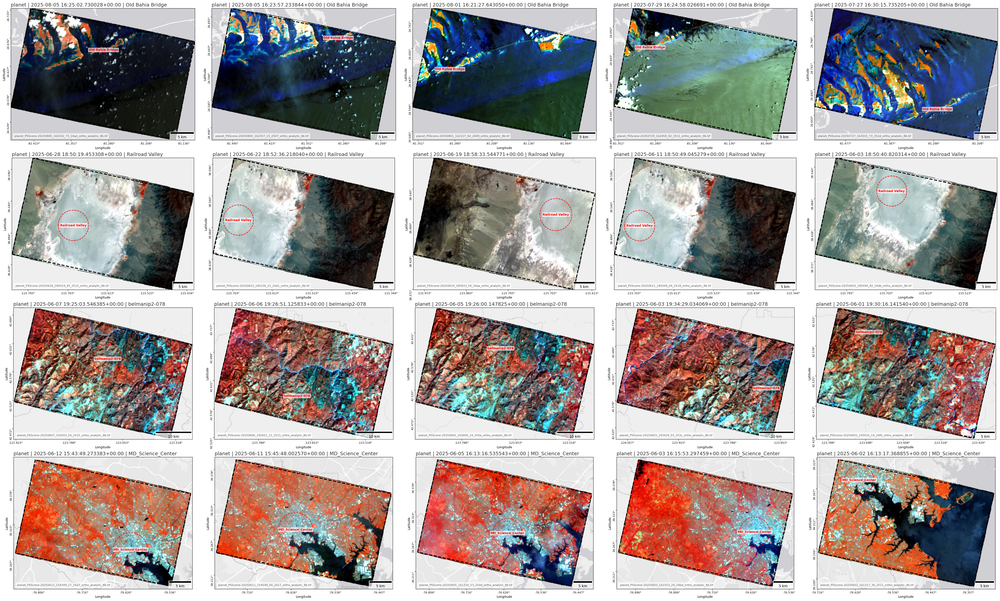

In [12]:
PLOT_LIMIT = 20
plot_infos = download_info_list[:PLOT_LIMIT]
if not plot_infos:
    print("No complete datasets were downloaded successfully; nothing to plot.")
else:
    ncols = min(SELECT_TOP_PER_SITE, len(plot_infos))
    nrows = (len(plot_infos) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 6 * nrows), squeeze=False)
    axes_flat = axes.ravel()
    for axis, info in zip(axes_flat, plot_infos):
        raster_key = info["chosen"]["ortho_analytic_8b"]
        rgb = [7, 6, 3] if "8b" in raster_key.lower() else [3, 2, 1]
        plot_image(
            local_path=info["local_path"],
            stac_gdf=info["stac_gdf"],
            sites_gdf=info["sites_gdf"],
            item_id=info["item_id"],
            rgb_indices=rgb,
            max_dim=512,
            ax=axis,
        )
    for axis in axes_flat[len(plot_infos):]:
        axis.set_visible(False)
    plt.tight_layout()
    plt.show()